In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# Load MNIST using the alternative ARFF parser
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

# Extract images and labels
X = mnist.data
y = mnist.target.astype(int)

# Preserve the original MNIST train/test split
X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)


Training data: (60000, 784)
Test data: (10000, 784)
Training labels: (60000,)
Test labels: (10000,)


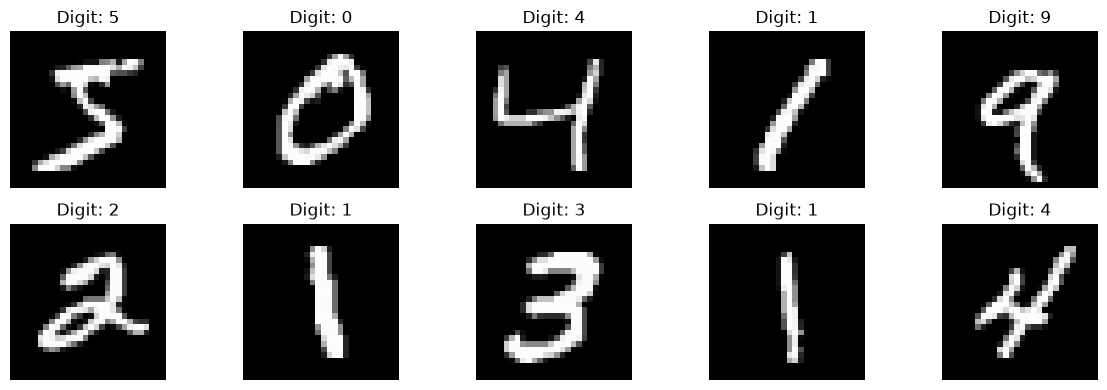

In [3]:

# Display 10 handwritten digits from MNIST

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_train[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:

# Step 4: Normalise MNIST data

X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Training shape: (60000, 784)
Testing shape: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:

# Step 5: Find the best k using cross-validation

import time
import pandas as pd

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

k_values = [1, 3, 5, 7, 9]

knn = KNeighborsClassifier(
    metric="euclidean",
    algorithm="brute",
    n_jobs=1
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn,
    param_grid={"n_neighbors": k_values},
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    verbose=2
)

start_time = time.time()

grid_search.fit(X_train, y_train)

elapsed_time = time.time() - start_time

print("\nBest k:", grid_search.best_params_["n_neighbors"])
print(f"Best validation accuracy: {grid_search.best_score_:.4f}")
print(f"Total time: {elapsed_time:.2f} seconds")


Fitting 3 folds for each of 5 candidates, totalling 15 fits
[CV] END ......................................n_neighbors=1; total time=   3.7s
[CV] END ......................................n_neighbors=1; total time=   3.5s
[CV] END ......................................n_neighbors=1; total time=   3.3s
[CV] END ......................................n_neighbors=3; total time=   3.2s
[CV] END ......................................n_neighbors=3; total time=   3.3s
[CV] END ......................................n_neighbors=3; total time=   3.3s
[CV] END ......................................n_neighbors=5; total time=   3.2s
[CV] END ......................................n_neighbors=5; total time=   3.2s
[CV] END ......................................n_neighbors=5; total time=   3.4s
[CV] END ......................................n_neighbors=7; total time=   3.2s
[CV] END ......................................n_neighbors=7; total time=   3.2s
[CV] END ......................................n_

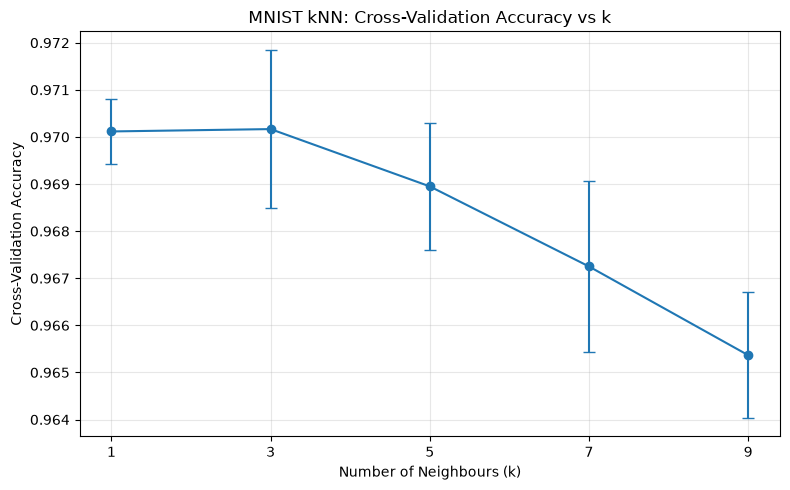

 param_n_neighbors  mean_test_score  std_test_score
                 1         0.970117        0.000685
                 3         0.970167        0.001684
                 5         0.968950        0.001350
                 7         0.967250        0.001806
                 9         0.965367        0.001336


In [6]:

# Step 6: Plot validation accuracy against k

results = pd.DataFrame(grid_search.cv_results_)

mean_accuracy = results["mean_test_score"].to_numpy()
std_accuracy = results["std_test_score"].to_numpy()

plt.figure(figsize=(8, 5))

plt.errorbar(
    k_values,
    mean_accuracy,
    yerr=std_accuracy,
    marker="o",
    capsize=4
)

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Cross-Validation Accuracy")
plt.title("MNIST kNN: Cross-Validation Accuracy vs k")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("knn_accuracy.png", dpi=300)
plt.show()

print(results[[
    "param_n_neighbors",
    "mean_test_score",
    "std_test_score"
]].to_string(index=False))


In [7]:

# Step 7: Evaluate the best kNN model on the test set

import time
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Get the best classifier selected by cross-validation
best_knn = grid_search.best_estimator_

print("Selected k:", grid_search.best_params_["n_neighbors"])

# Predict the 10,000 test images
start_time = time.time()
y_pred = best_knn.predict(X_test)
prediction_time = time.time() - start_time

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")
print(f"Prediction time: {prediction_time:.2f} seconds")

print("\nClassification report:")
print(classification_report(y_test, y_pred))


Selected k: 3
Test accuracy: 0.9705
Test accuracy (%): 97.05%
Prediction time: 2.87 seconds

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.98      0.97      0.97      1032
           3       0.96      0.97      0.96      1010
           4       0.98      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.99      0.94      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



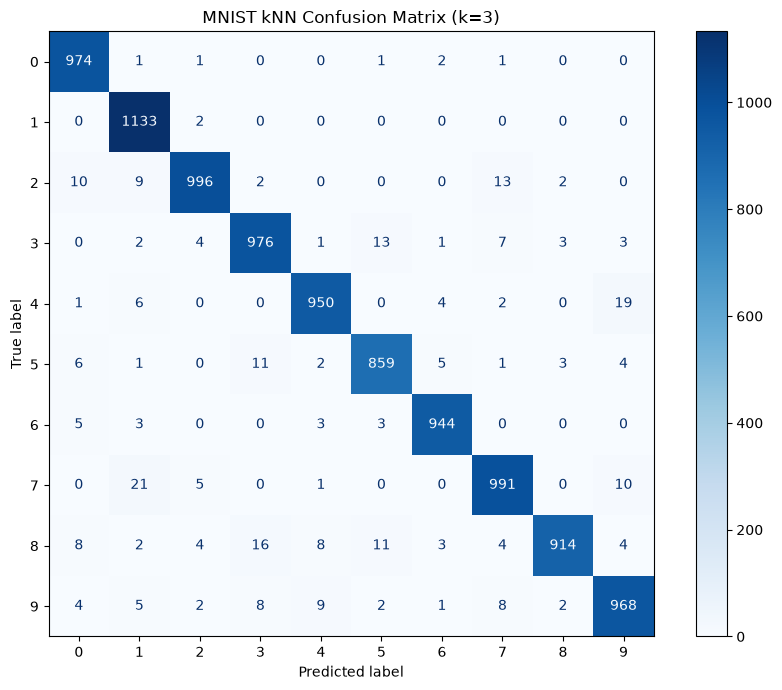

In [8]:

# Step 8: Confusion matrix

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=range(10),
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("MNIST kNN Confusion Matrix (k=3)")
plt.tight_layout()
plt.savefig("knn_confusion_matrix.png", dpi=300)
plt.show()
